# Практическая работа 7. Дневная выручка магазина

Вариант 8

Расчёт по формуле методички охватывает все статусы. Дневная выручка здесь означает сумму оформленных заказов, включая отменённые и возвращённые. Дату берём из `order_datetime` в том виде, в котором она записана в CSV.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from shop_data import read_orders

orders = read_orders()
orders["order_date"] = orders["order_datetime"].dt.normalize()
orders["revenue"] = orders["price"] * orders["quantity"]

### 1. Сумма заказов по дате

In [2]:
daily = orders.groupby("order_date").agg(
    revenue=("revenue", "sum"),
    orders_count=("order_id", "nunique"),
    units=("quantity", "sum"),
).asfreq("D", fill_value=0)
daily["avg_order"] = daily["revenue"].div(daily["orders_count"].replace(0, float("nan")))

print("Дней в таблице:", len(daily))
daily.head().round(2)

Дней в таблице: 91


,revenue,orders_count,units,avg_order
order_date,,,,
2024-01-01,4483590.00,164,406,27338.96
2024-01-02,4095217.58,158,411,25919.10
2024-01-03,4425023.45,168,424,26339.43
2024-01-04,3747060.38,176,431,21290.12
2024-01-05,4623480.03,176,432,26269.77


### 2. Динамика за квартал

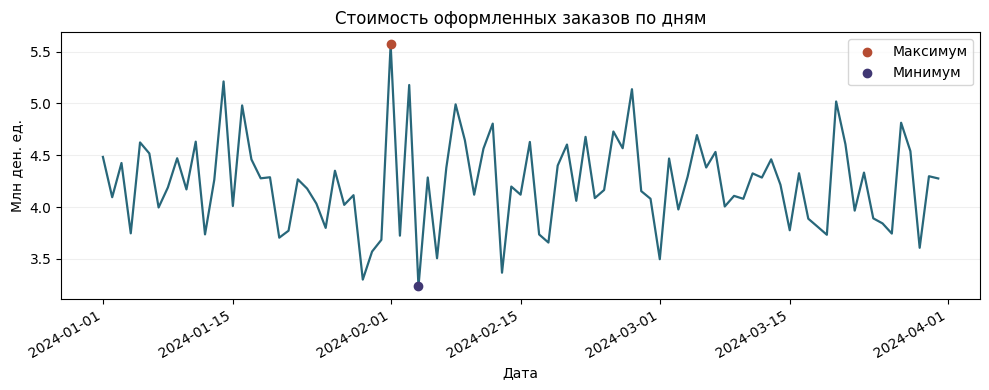

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily["revenue"] / 1_000_000, color="#28677a", linewidth=1.6)
for label, day, color in [
    ("Максимум", daily["revenue"].idxmax(), "#b54c32"),
    ("Минимум", daily["revenue"].idxmin(), "#403773"),
]:
    ax.scatter(day, daily.at[day, "revenue"] / 1_000_000, color=color, label=label, zorder=3)
ax.set(title="Стоимость оформленных заказов по дням", xlabel="Дата", ylabel="Млн ден. ед.")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### 3–4. Даты максимума и минимума

In [4]:
peak = daily.loc[daily["revenue"].eq(daily["revenue"].max())]
low = daily.loc[daily["revenue"].eq(daily["revenue"].min())]
pd.concat({"Максимум": peak, "Минимум": low}).round(2)

,,revenue,orders_count,units,avg_order
,order_date,,,,
Максимум,2024-02-01,5568238.96,202,523,27565.54
Минимум,2024-02-04,3234544.34,138,342,23438.73


### 5. Чем различаются эти дни

1 февраля сумма заказов достигла **5 568 238,96**, а 4 февраля составила **3 234 544,34**. В первом случае покупатели оформили 202 заказа на 523 единицы товара, во втором — 138 заказов на 342 единицы. Средняя сумма заказа тоже была выше в день максимума — 27 565,54 против 23 438,73. Разницу объясняют и число заказов, и их стоимость. Сведений о скидках и рекламе в файлах нет, поэтому связать пик с конкретной акцией нельзя.